# 03 · OSM + WorldCover 特征（GreenPath）

**这一步做什么**：对 01、02 产出的每个格子，统计它所覆盖的那块地面（和卫星图同样大的方块）里的**客观地理特征**：
道路按等级的长度、自行车道长度、平均车道数、路口数、POI 数、水体 / 绿地 / 建筑的面积占比，以及 ESA WorldCover 土地覆盖各类占比。

这些特征有两个用途：
- **作为模型输入 X 的一部分**（和卫星图一起），也是强基线 B1（LightGBM 只用 OSM 特征）的全部输入；
- 以后给路线打分时，水体、绿地、自行车道这类客观维度直接用它们，不需要模型预测。

| | 路径（相对数据根目录） |
|---|---|
| 输入：格子主表 | `processed/cells.parquet`（来自 01、02） |
| 输出：OSM / WorldCover 特征 | `processed/osm_features.parquet` |
| 输出：运行记录 | `runs/{时间戳}/03_osm_features_manifest.json` |

数据来源：OpenStreetMap（ODbL，需注明 © OpenStreetMap contributors；Geofabrik 每日快照）、ESA WorldCover 2021 v200（CC-BY 4.0，通过 Planetary Computer 读取）。
**不需要 GPU。** OSM 数据来自 Geofabrik 的本地快照文件（`raw/osm/*.osm.pbf`，约 300 MB，只下载一次），不依赖 Overpass 公共服务器。

## 1. 安装依赖（只在 Colab 里会执行）

In [ ]:
import sys, subprocess
if "google.colab" in sys.modules:      # 只有在 Colab 里才自动安装；本地环境请提前装好
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "h3>=4", "pyrosm", "geopandas", "pystac-client", "planetary-computer", "rasterio", "pyproj", "shapely", "gcsfs", "pyarrow", "pandas", "matplotlib", "tqdm", "fsspec"], check=True)

## 2. 配置
- `GROUND_M`：统计的方块边长。优先使用 02 写进格子表的 `ground_m`，保证特征和卫星图覆盖**同一块地**；这里只是兜底。
- `OSM_PAD_DEG`：在格子范围外多取一圈，避免边缘格子的道路被截断。
- `OSM_PBF_URL`：OSM 的离线快照文件（Geofabrik 每天更新，按州 / 国家切分）。第一次运行会自动下载，约 300 MB；之后直接读本地文件。
  换城市时换成对应的州，例如 Providence 用 `.../north-america/us/rhode-island-latest.osm.pbf`。

In [ ]:
GROUND_M = 154
OSM_PAD_DEG = 0.004
WORLDCOVER_YEAR = 2021
OSM_PBF_URL = "https://download.geofabrik.de/north-america/us/massachusetts-latest.osm.pbf"

STORAGE = "local"                              # "local" | "gcs" | "drive"
GCS_ROOT = "gs://greenpath-data"
DRIVE_ROOT = "/content/drive/MyDrive/greenpath-data"
LOCAL_ROOT = "./data"

## 3. 连接存储并读入格子表

In [ ]:
import os, io, json, datetime
import fsspec
import pandas as pd

STORAGE_OPTS = {}
if STORAGE == "gcs":
    try:
        from google.colab import auth
        auth.authenticate_user()                 # Colab 里登录；本地请先 gcloud auth application-default login
    except ImportError:
        pass
    ROOT = GCS_ROOT
    STORAGE_OPTS = {"token": "google_default"}
    fs = fsspec.filesystem("gcs", **STORAGE_OPTS)
elif STORAGE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = DRIVE_ROOT
    fs = fsspec.filesystem("file")
else:
    ROOT = os.environ.get("GREENPATH_ROOT", LOCAL_ROOT)   # 以后容器里用环境变量指定数据目录
    fs = fsspec.filesystem("file")

def path(*parts):
    # 拼出数据根目录下的完整路径，例如 path("processed", "cells.parquet")
    return "/".join([ROOT.rstrip("/"), *parts])

def makedirs(p):
    if STORAGE != "gcs":            # GCS 没有真正的目录，不需要创建
        os.makedirs(p, exist_ok=True)

def read_parquet(p):
    return pd.read_parquet(p, storage_options=STORAGE_OPTS or None)

def write_parquet(df, p):
    df.to_parquet(p, index=False, storage_options=STORAGE_OPTS or None)

def write_manifest(manifest, name):
    run_ts = datetime.datetime.utcnow().strftime("%Y-%m-%dT%H-%M")
    makedirs(path("runs", run_ts))
    with fs.open(path("runs", run_ts, name), "w") as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)
    return manifest

try:                                          # 图里的中文用系统自带的中文字体显示
    import matplotlib
    matplotlib.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "Arial Unicode MS", "Noto Sans CJK SC",
                                              "Microsoft YaHei", "SimHei", "DejaVu Sans"]
    matplotlib.rcParams["axes.unicode_minus"] = False
except ImportError:
    pass

now_iso = lambda: datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"
print("数据根目录:", ROOT)

数据根目录: ./data


In [ ]:
import numpy as np
cells = read_parquet(path("processed", "cells.parquet"))
if "tile_ok" in cells:
    cells = cells[cells.tile_ok.fillna(False)]           # 只处理已经有卫星图的格子
cells = cells.reset_index(drop=True)
if "ground_m" in cells and cells.ground_m.notna().any():
    GROUND_M = float(cells.ground_m.dropna().iloc[0])
print(f"{len(cells)} 个格子，每格统计 {GROUND_M:.0f} m × {GROUND_M:.0f} m 的方块")

1126 个格子，每格统计 154 m × 154 m 的方块


## 4. 每个格子的"统计方块"
以格子中心为中心、边长 `GROUND_M` 的正方形，先投影到当地的 UTM 坐标（单位米），这样长度和面积才是真实的米和平方米。

In [ ]:
import geopandas as gpd

pts = gpd.GeoSeries(gpd.points_from_xy(cells.lon, cells.lat), crs=4326)
UTM = pts.estimate_utm_crs()
foot = gpd.GeoDataFrame({"h3_index": cells.h3_index},
                        geometry=pts.to_crs(UTM).buffer(GROUND_M / 2, cap_style="square"), crs=UTM)
FOOT_AREA = GROUND_M ** 2
west, south, east, north = pts.total_bounds
OSM_BBOX = (west - OSM_PAD_DEG, south - OSM_PAD_DEG, east + OSM_PAD_DEG, north + OSM_PAD_DEG)   # left, bottom, right, top
print("UTM 分带:", UTM.to_string()[:40], "| OSM 下载范围:", [round(v, 4) for v in OSM_BBOX])

UTM 分带: EPSG:32619 | OSM 下载范围: [np.float64(-71.1332), np.float64(42.3262), np.float64(-71.0387), np.float64(42.3938)]


## 5. 读取 OSM（本地快照文件）
不再向 Overpass 公共服务器发请求（它经常拒绝连接或排队很久），而是用 Geofabrik 的**每日快照** `.pbf`：同样是 OpenStreetMap 的数据，下载一次，之后在本地读取。
好处：不依赖外部服务器、速度快（整套几十秒）、**文件固定，实验可复现**。第一次运行时会把文件和下载日期记在 `raw/osm/` 里。

- **道路网络**：`pyrosm` 的 `get_network`，保留车道数、限速、自行车道相关标签；道路在每个节点处断开，所以能数出路口。
- **面状要素**：水体、公园 / 绿地 / 林地、建筑。
- **点状要素**：POI（amenity / shop / tourism），统一取代表点，保证每个 POI 只算在一个格子里。

In [ ]:
import requests, time, warnings
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

PBF_NAME = OSM_PBF_URL.rsplit("/", 1)[-1]
META_REL = f"raw/osm/{PBF_NAME}.meta.json"
# pyrosm 需要本地文件；本地 / Drive 模式直接放进数据目录，GCS 模式放在本地缓存目录
PBF = path("raw", "osm", PBF_NAME) if STORAGE != "gcs" else os.path.join("cache", PBF_NAME)
makedirs(os.path.dirname(PBF) or ".")

if not os.path.exists(PBF):
    print(f"下载 {OSM_PBF_URL}")
    with requests.get(OSM_PBF_URL, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        meta = {"url": OSM_PBF_URL, "last_modified": r.headers.get("last-modified"),
                "downloaded_at": now_iso(), "size_bytes": total}
        with open(PBF + ".part", "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc=PBF_NAME) as pb:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk); pb.update(len(chunk))
    os.replace(PBF + ".part", PBF)
    with fs.open(path(META_REL), "w") as f:
        json.dump(meta, f, indent=2)

try:
    with fs.open(path(META_REL), "r") as f:
        OSM_META = json.load(f)
except Exception:                                       # 文件是手动放进来的，没有下载记录
    OSM_META = {"url": OSM_PBF_URL, "size_bytes": os.path.getsize(PBF),
                "note": "手动放入，无下载记录", "file_mtime": datetime.datetime.fromtimestamp(os.path.getmtime(PBF)).isoformat()}
print("OSM 快照：", OSM_META.get("last_modified") or OSM_META.get("file_mtime"), f"（{os.path.getsize(PBF) / 1e6:.0f} MB）")

OSM 快照： Mon, 12 Oct 2026 03:52:24 GMT （311 MB）


In [ ]:
import pyrosm

osm = pyrosm.OSM(PBF, bounding_box=list(OSM_BBOX))        # [left, bottom, right, top]，只读这个范围

bar = tqdm(total=5, desc="读取 OSM", bar_format="{l_bar}{bar} {n_fmt}/{total_fmt} [{elapsed}] {postfix}")
def step(label, fn):
    # 每一步前在进度条上标出正在做什么，完成后打印耗时
    bar.set_postfix_str(f"正在读取：{label}")
    t0 = time.time()
    out = fn()
    bar.update(1)
    tqdm.write(f"  ✓ {label}（{time.time() - t0:.0f} 秒）")
    return out

def layer(tags):
    g = osm.get_data_by_custom_criteria(custom_filter=tags, filter_type="keep",
                                        keep_nodes=False, keep_ways=True, keep_relations=True)
    if g is None or len(g) == 0:
        return gpd.GeoDataFrame(geometry=[], crs=4326).to_crs(UTM)
    return g[["geometry"]].reset_index(drop=True).to_crs(UTM)

def load_roads():
    return osm.get_network(network_type="all", nodes=True,
                           extra_attributes=["lanes", "maxspeed", "cycleway", "cycleway:left", "cycleway:right", "cycleway:both"])

def load_pois():
    p = osm.get_pois(custom_filter={"amenity": True, "shop": True, "tourism": True})
    if p is None or len(p) == 0:
        return gpd.GeoDataFrame(geometry=[], crs=4326).to_crs(UTM)
    p = p[["geometry"]].to_crs(UTM).reset_index(drop=True)
    p["geometry"] = p.geometry.representative_point()      # 面状 POI（如商场）取代表点，只算一次
    return p

nodes, edges = step("道路网络", load_roads)
edges = edges.to_crs(UTM).reset_index(drop=True)
degree = pd.concat([edges.u, edges.v]).value_counts()      # 每个节点连着几条路段；≥3 就是路口
nodes = nodes.to_crs(UTM)
nodes["street_count"] = nodes.id.map(degree).fillna(0).astype(int)
water = step("水体", lambda: layer({"natural": ["water", "wetland"], "waterway": ["riverbank", "dock"], "landuse": ["reservoir", "basin"]}))
green = step("绿地", lambda: layer({"leisure": ["park", "garden", "playground", "recreation_ground", "nature_reserve", "golf_course"],
                                    "landuse": ["grass", "meadow", "forest", "village_green", "recreation_ground", "cemetery"],
                                    "natural": ["wood", "scrub", "grassland"]}))
buildings = step("建筑", lambda: layer({"building": True}))
pois = step("POI", load_pois)
bar.set_postfix_str("完成"); bar.close()
print(f"道路 {len(edges)} 段，路口节点 {int((nodes.street_count >= 3).sum())} 个")
print(f"水体 {len(water)} | 绿地 {len(green)} | 建筑 {len(buildings)} | POI {len(pois)}")

读取 OSM:   0%|           0/5 [00:00] 

Reading massachusetts-latest.osm.pbf:  64%|######4   | 200M/311M [00:02<00:01, 99.5MB/s]

  ✓ 道路网络（13 秒）


Reading massachusetts-latest.osm.pbf:  73%|#######2  | 227M/311M [00:02<00:00, 113MB/s]

  ✓ 水体（4 秒）


...

  ✓ 绿地（5 秒）


Reading massachusetts-latest.osm.pbf:  68%|######7   | 210M/311M [00:02<00:00, 105MB/s]

  ✓ 建筑（10 秒）


Reading massachusetts-latest.osm.pbf:  54%|#####3    | 168M/311M [00:02<00:01, 83.7MB/s]

  ✓ POI（5 秒）
道路 209330 段，路口节点 49837 个
水体 78 | 绿地 3208 | 建筑 45843 | POI 17799


## 6. 逐格子统计
道路按等级分 4 类：`major`（高速 / 快速路 / 主干道）、`secondary`（次干道和三级路）、`local`（居住区街道、服务道路）、`path`（步道、自行车道、小径）。
`bike_lane_m` 包括独立的自行车道，以及机动车道上标注了自行车道的路段。
面积占比 = 要素与方块相交的面积 ÷ 方块面积（同类要素重叠只算一次）。

In [ ]:
CLASSES = {
    "major": {"motorway", "motorway_link", "trunk", "trunk_link", "primary", "primary_link"},
    "secondary": {"secondary", "secondary_link", "tertiary", "tertiary_link"},
    "local": {"residential", "unclassified", "living_street", "service"},
    "path": {"cycleway", "footway", "path", "pedestrian", "track", "steps", "bridleway"},
}

def first(v):                                   # 个别标签可能是列表，取第一个
    return v[0] if isinstance(v, (list, tuple)) else v

def road_class(h):
    h = first(h)
    return next((k for k, s in CLASSES.items() if h in s), "other")

def has_bike(row):
    if first(row.get("highway")) == "cycleway":
        return True
    for c in ("cycleway", "cycleway:left", "cycleway:right", "cycleway:both"):
        v = first(row.get(c))
        if isinstance(v, str) and v not in ("no", "none", "separate"):
            return True
    return False

def to_num(v):
    v = first(v)
    try:
        return float(str(v).split()[0])
    except (ValueError, TypeError, IndexError):
        return np.nan

edges["rclass"] = edges.highway.map(road_class)
edges["bike"] = edges.apply(has_bike, axis=1)
edges["lanes_n"] = edges["lanes"].map(to_num) if "lanes" in edges else np.nan
edges["speed"] = edges["maxspeed"].map(to_num) if "maxspeed" in edges else np.nan
inter_nodes = nodes[nodes.street_count >= 3]

def area_frac(layer, fp):
    if layer.empty:
        return 0.0
    cand = layer.iloc[layer.sindex.query(fp, predicate="intersects")]
    if cand.empty:
        return 0.0
    return float(min(cand.geometry.intersection(fp).union_all().area / fp.area, 1.0))

def wmean(values, weights):
    ok = values.notna()
    return float(np.average(values[ok], weights=weights[ok])) if ok.any() and weights[ok].sum() > 0 else np.nan

rows = []
for h3_index, fp in zip(foot.h3_index, foot.geometry):
    e = edges.iloc[edges.sindex.query(fp, predicate="intersects")].copy()
    e["len_in"] = e.geometry.intersection(fp).length
    row = {"h3_index": h3_index}
    for k in list(CLASSES) + ["other"]:
        row[f"road_{k}_m"] = float(e.loc[e.rclass == k, "len_in"].sum())
    row["road_total_m"] = float(e.len_in.sum())
    row["bike_lane_m"] = float(e.loc[e.bike, "len_in"].sum())
    drive = e[e.rclass.isin(["major", "secondary", "local"])]
    row["lanes_avg"] = wmean(drive.lanes_n, drive.len_in)
    row["maxspeed_avg"] = wmean(drive.speed, drive.len_in)
    row["intersections"] = int(len(inter_nodes.iloc[inter_nodes.sindex.query(fp, predicate="intersects")]))
    row["poi_count"] = int(len(pois.iloc[pois.sindex.query(fp, predicate="intersects")])) if len(pois) else 0
    row["osm_water_frac"] = area_frac(water, fp)
    row["osm_green_frac"] = area_frac(green, fp)
    row["osm_building_frac"] = area_frac(buildings, fp)
    rows.append(row)

osm_feat = pd.DataFrame(rows)
osm_feat.describe().T[["mean", "min", "50%", "max"]].round(2)

,mean,min,50%,max
road_major_m,280.92,0.0,188.65,2351.19
road_secondary_m,83.37,0.0,14.29,644.33
road_local_m,311.44,0.0,295.96,1046.59
road_path_m,817.74,0.0,843.80,2423.60
road_other_m,12.58,0.0,0.00,973.21
road_total_m,1506.04,0.0,1509.85,3547.88
bike_lane_m,187.61,0.0,160.69,853.41
lanes_avg,2.01,1.0,1.95,5.19
maxspeed_avg,26.83,7.0,25.00,55.00
intersections,25.50,0.0,25.00,98.00


## 7. WorldCover 土地覆盖占比
ESA WorldCover 是 10 m 分辨率的全球土地覆盖分类（树、灌木、草地、农田、建成区、裸地、水体、湿地等）。
对每个方块读出对应的几百个像素，统计各类别的占比，并记录占比最大的类别（`wc_dominant`）。

In [ ]:
import planetary_computer, pystac_client, rasterio
from rasterio.windows import Window
from shapely.geometry import shape, Point
from tqdm.auto import tqdm

WC = {10: "tree", 20: "shrub", 30: "grass", 40: "crop", 50: "built", 60: "bare",
      70: "snow", 80: "water", 90: "wetland", 95: "mangrove", 100: "moss"}

catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                    modifier=planetary_computer.sign_inplace)
wc_items = list(catalog.search(collections=["esa-worldcover"], bbox=OSM_BBOX,
                               datetime=f"{WORLDCOVER_YEAR}-01-01/{WORLDCOVER_YEAR}-12-31").items())
print(f"找到 {len(wc_items)} 幅 WorldCover 影像")
wc_geoms = [(shape(it.geometry), it) for it in wc_items]
foot_ll = foot.to_crs(4326)

wc_rows = []
for it_geom, it in wc_geoms:
    idx = [i for i, c in enumerate(cells.itertuples()) if it_geom.contains(Point(c.lon, c.lat))]
    if not idx:
        continue
    href = planetary_computer.sign(it.assets["map"].href)
    with rasterio.open(href) as src:
        for i in tqdm(idx, desc=it.id[-12:]):
            minx, miny, maxx, maxy = foot_ll.geometry.iloc[i].bounds
            r0, c0 = src.index(minx, maxy); r1, c1 = src.index(maxx, miny)
            arr = src.read(1, window=Window(c0, r0, max(c1 - c0 + 1, 1), max(r1 - r0 + 1, 1)))
            counts = np.bincount(arr.ravel(), minlength=101)
            tot = max(counts.sum(), 1)
            row = {"h3_index": cells.h3_index.iloc[i]}
            for code_, name in WC.items():
                row[f"wc_{name}_frac"] = float(counts[code_] / tot)
            row["wc_dominant"] = WC.get(int(arr.ravel()[np.argmax(np.bincount(arr.ravel()))]) if arr.size else 0, "unknown")
            wc_rows.append(row)

wc_feat = pd.DataFrame(wc_rows)
print(f"WorldCover 覆盖 {len(wc_feat)} / {len(cells)} 个格子")
wc_feat.wc_dominant.value_counts()

找到 1 幅 WorldCover 影像


v200_N42W072:   0%|          | 0/1126 [00:00<?, ?it/s]

WorldCover 覆盖 1126 / 1126 个格子


wc_dominant
built      800
tree       213
water       74
grass       35
wetland      2
bare         1
crop         1
Name: count, dtype: int64

## 8. 合并并写出
`osm_features.parquet` 每个格子一行，用 `h3_index` 和格子主表对齐。

In [ ]:
feat = cells[["cell_id", "h3_index"]].merge(osm_feat, on="h3_index", how="left").merge(wc_feat, on="h3_index", how="left")
feat["updated_at"] = now_iso()
write_parquet(feat, path("processed", "osm_features.parquet"))
print(f"osm_features.parquet：{len(feat)} 行，{feat.shape[1] - 3} 个特征列")
print("缺失值最多的列：")
print(feat.isna().sum().sort_values(ascending=False).head(5).to_string())
feat.head()

osm_features.parquet：1126 行，26 个特征列
缺失值最多的列：
lanes_avg       33
maxspeed_avg    30
cell_id          0
wc_tree_frac     0
wc_dominant      0


,cell_id,h3_index,road_major_m,road_secondary_m,road_local_m,road_path_m,road_other_m,road_total_m,bike_lane_m,lanes_avg,...,wc_crop_frac,wc_built_frac,wc_bare_frac,wc_snow_frac,wc_water_frac,wc_wetland_frac,wc_mangrove_frac,wc_moss_frac,wc_dominant,updated_at
0,BOS_8a2a3064000ffff,8a2a3064000ffff,314.792489,154.973928,357.877422,983.854010,0.0,1811.497849,272.439696,2.135091,...,0.0,0.759259,0.0,0.0,0.0,0.0,0.0,0.0,built,2026-10-12T23:17:21Z
1,BOS_8a2a3064014ffff,8a2a3064014ffff,296.118564,166.584928,104.588108,659.185024,0.0,1226.476624,0.000000,2.000000,...,0.0,0.458333,0.0,0.0,0.0,0.0,0.0,0.0,built,2026-10-12T23:17:21Z
2,BOS_8a2a3064015ffff,8a2a3064015ffff,315.310099,0.000000,458.616696,837.150900,0.0,1611.077694,0.000000,2.000000,...,0.0,0.800926,0.0,0.0,0.0,0.0,0.0,0.0,built,2026-10-12T23:17:21Z
3,BOS_8a2a3064016ffff,8a2a3064016ffff,315.713945,75.261144,96.575289,602.860458,0.0,1090.410836,0.000000,1.962373,...,0.0,0.655093,0.0,0.0,0.0,0.0,0.0,0.0,tree,2026-10-12T23:17:21Z
4,BOS_8a2a30640807fff,8a2a30640807fff,0.000000,289.633792,413.108767,1237.069236,0.0,1939.811794,172.758534,1.587391,...,0.0,0.379630,0.0,0.0,0.0,0.0,0.0,0.0,built,2026-10-12T23:17:21Z


## 9. 质检：特征和直觉对不对
抽几个格子，把卫星图和主要特征并排放在一起看：主干道多的地方卫星图里应该能看到宽路和车，`osm_water_frac` 高的地方应该能看到水面。

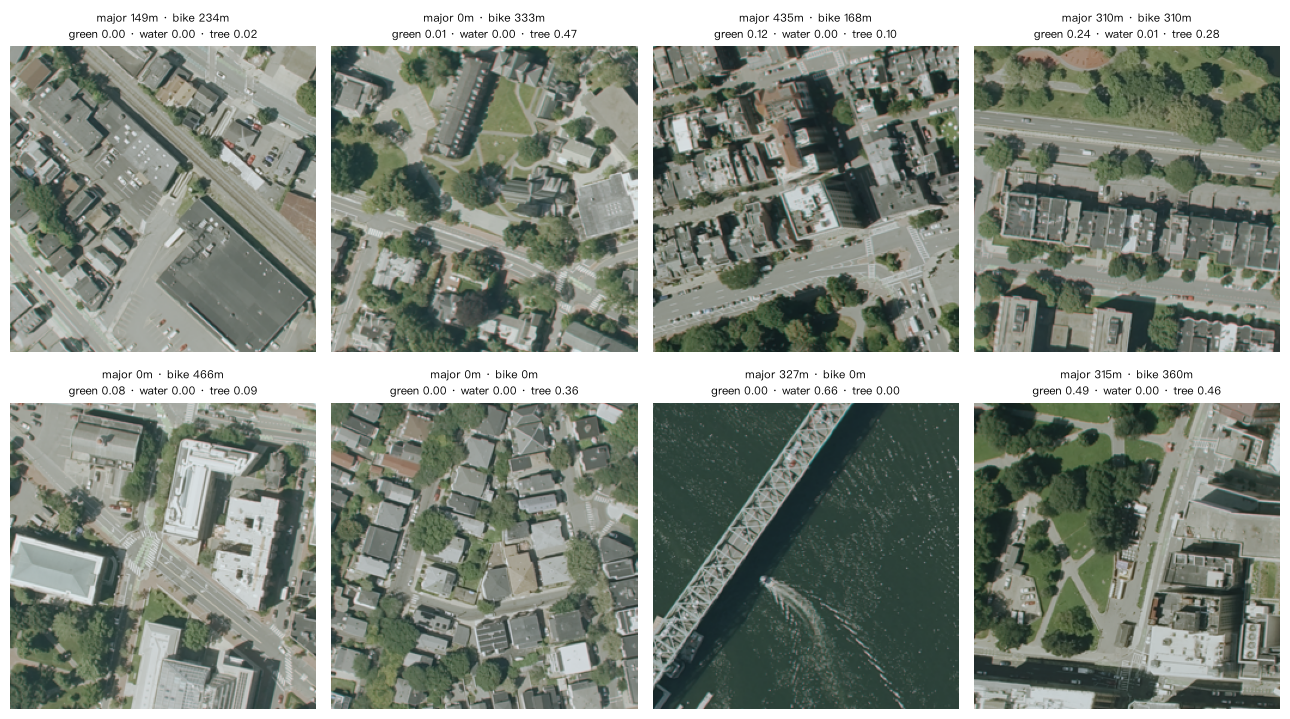

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

show = feat.merge(cells[["h3_index", "tile_path"]], on="h3_index").sample(n=min(8, len(feat)), random_state=42)
fig, axes = plt.subplots(2, 4, figsize=(13, 7.5))
for ax in axes.ravel():
    ax.axis("off")
for ax, r in zip(axes.ravel(), show.itertuples()):
    with fs.open(path(r.tile_path), "rb") as f:
        ax.imshow(Image.open(f))
    ax.set_title(f"major {r.road_major_m:.0f}m · bike {r.bike_lane_m:.0f}m\n"
                 f"green {r.osm_green_frac:.2f} · water {r.osm_water_frac:.2f} · tree {r.wc_tree_frac:.2f}", fontsize=8)
plt.tight_layout(); plt.show()

## 10. 运行记录

In [ ]:
manifest = write_manifest({
    "step": "03_osm_features", "input_cells": int(len(cells)), "output_rows": int(len(feat)),
    "ground_m": GROUND_M, "osm_bbox": [round(v, 5) for v in OSM_BBOX],
    "osm_road_segments": int(len(edges)), "osm_buildings": int(len(buildings)), "osm_pois": int(len(pois)),
    "worldcover_year": WORLDCOVER_YEAR, "worldcover_cells": int(len(wc_feat)),
    "attribution": "© OpenStreetMap contributors (ODbL); ESA WorldCover 2021 v200 (CC BY 4.0)",
    "osm_snapshot": OSM_META, "pyrosm_version": pyrosm.__version__,
    "outputs": ["processed/osm_features.parquet"],
    "finished_at": now_iso(),
}, "03_osm_features_manifest.json")
print(json.dumps(manifest, indent=2, ensure_ascii=False))

{
  "step": "03_osm_features",
  "input_cells": 1126,
  "output_rows": 1126,
  "ground_m": 154.0,
  "osm_bbox": [
    -71.13315,
    42.32622,
    -71.03869,
    42.39383
  ],
  "osm_road_segments": 209330,
  "osm_buildings": 45843,
  "osm_pois": 17799,
  "worldcover_year": 2021,
  "worldcover_cells": 1126,
  "attribution": "© OpenStreetMap contributors (ODbL); ESA WorldCover 2021 v200 (CC BY 4.0)",
  "osm_snapshot": {
    "url": "https://download.geofabrik.de/north-america/us/massachusetts-latest.osm.pbf",
    "last_modified": "Mon, 12 Oct 2026 03:52:24 GMT",
    "downloaded_at": "2026-10-12T20:27:00Z",
    "size_bytes": 310967666,
    "note": "downloaded manually with curl by the assistant before notebook 03 was switched to the local snapshot"
  },
  "pyrosm_version": "0.19.1",
  "outputs": [
    "processed/osm_features.parquet"
  ],
  "finished_at": "2026-10-12T23:17:21Z"
}


## 下一步
- OSM 是动态更新的数据，**要复现结果就要记下下载日期**（上面的运行记录里有时间戳）；正式数据集可以把下载的 OSM 另存一份。
- 下一个 notebook：`04_labeling`，用 Gemini 给每个格子的街景打分，生成标签 Y。